# 03 Baseline klasik (Fase 2): fitur buatan tangan dan *gradient boosting*

Notebook ini membuat model pembanding sederhana sebelum model *deep learning*. Dari setiap *epoch* dihitung 33 angka ringkasan berdasarkan ilmu tidur dan pemrosesan sinyal (daya pita frekuensi, bentuk gelombang, gerakan mata, tingkat otot), lalu *gradient boosting* belajar menimbang angka-angka itu. Hasilnya menjadi **batas bawah** yang harus dilampaui model di Fase 3.

| Bagian | Isi singkat |
|---|---|
| A | Konfigurasi dan parameter tetap |
| B | Fungsi fitur dan uji pada satu rekaman |
| C | Ekstraksi fitur seluruh 153 rekaman dan penyimpanan |
| D | Pemeriksaan fitur per tahap tidur |
| E | Fitur konteks (±2 *epoch* tetangga) |
| F | Model, metrik, dan skema validasi berbasis subjek |
| G | Hasil utama pada SC-20 dan SC-78 |
| H | Analisis tambahan: ablasi modalitas, kebocoran data, pentingnya fitur, skor per subjek |
| I | Penyimpanan hasil |

**Cara memakai.** Notebook 02 harus sudah dijalankan karena notebook ini membaca *cache* `data/processed/sc/`. Jalankan sel berurutan dari atas; satu kali jalan sekitar 25 menit di CPU (bagian terlama adalah SC-78 sekitar 11 menit). Di bawah setiap sel kode ada keterangan **Input**, **Output**, dan **Kesimpulan**. Berkas `data/processed/features_sc.npz` dan `data/processed/baseline_predictions.npz` diabaikan git dan dapat dibuat ulang.

## Bagian A. Konfigurasi

Memuat pustaka, menetapkan lokasi berkas, dan parameter tetap yang dipakai seluruh notebook.

In [ ]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import welch
from scipy.stats import kurtosis
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, cohen_kappa_score, confusion_matrix, f1_score
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, LeaveOneGroupOut

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts" / "edfx_eda.py").is_file())
CACHE = ROOT / "data" / "processed" / "sc"                         # Phase-1 cache, one .npz per recording
FEATURES = ROOT / "data" / "processed" / "features_sc.npz"         # written in section C (ignored by git)
PREDICTIONS = ROOT / "data" / "processed" / "baseline_predictions.npz"
MANIFEST = ROOT / "results" / "tables" / "02_cache_manifest.csv"   # Phase-1 quality flags per recording
FIG_DIR, TAB_DIR = ROOT / "results" / "figures", ROOT / "results" / "tables"

FS = 100            # Hz, EEG/EOG
IGNORE = -1         # label excluded from training and metrics (decision K1)
CONTEXT = 2         # neighbouring epochs added on each side (section E)
SEED = 0
STAGES = ["Wake", "N1", "N2", "N3", "REM"]
EXPECTED = [65_941, 21_522, 69_132, 13_039, 25_835]   # labelled epochs per stage after trimming (notebook 02)

STAGE_COLORS = dict(zip(STAGES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
MUTED, INK, INK_2, SURFACE, GRID = "#898781", "#0b0b0b", "#52514e", "#fcfcfb", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": ["Segoe UI", "DejaVu Sans"], "text.color": INK,
    "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titlelocation": "left", "axes.titleweight": "bold",
    "axes.titlesize": 12, "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
})
assert len(list(CACHE.glob("*.npz"))) == 153, "run notebook 02 first"
print("repo root:", ROOT)

repo root: d:\sleep-edfx


**Input.** Memuat pustaka, mencari folder repositori, menetapkan lokasi *cache* dari notebook 02 serta berkas keluaran, dan parameter tetap (label −1 diabaikan, konteks ±2 *epoch*, *seed* 0, jumlah *epoch* per kelas yang diharapkan).

**Output.** Alamat folder repositori. `assert` memastikan 153 berkas *cache* tersedia.

**Kesimpulan.** Lingkungan siap. Bila `assert` gagal, jalankan notebook 02 terlebih dahulu.

## Bagian B. Fungsi fitur

Mendefinisikan cara mengubah satu *epoch* menjadi 33 angka ringkasan, lalu mencobanya pada satu rekaman. Fitur ini dipilih kita sendiri berdasarkan ciri yang dipakai dokter untuk menilai tahap tidur, dihitung dengan rumus pemrosesan sinyal yang baku.

In [2]:
BANDS = {"delta1": (0.5, 2), "delta2": (2, 4), "theta": (4, 8),     # Hz; delta split into slow-wave and upper delta
         "alpha": (8, 12), "sigma": (12, 15), "beta": (15, 30)}


def safe_log(v):
    return np.log(np.maximum(v, 1e-8))


def spectrum(x):
    """Welch power spectral density per epoch (4 s Hann windows, 50% overlap); computed once per channel."""
    return welch(x, fs=FS, nperseg=4 * FS, axis=-1)


def band_power(f, p, low, high):
    """Sum of the spectrum over [low, high) Hz, one value per epoch."""
    return p[:, (f >= low) & (f < high)].sum(axis=1)


def hjorth(x):
    """Hjorth mobility (mean frequency) and complexity (change in frequency) per epoch."""
    dx, ddx = np.diff(x, axis=1), np.diff(x, n=2, axis=1)
    mobility = np.sqrt(dx.var(1) / np.maximum(x.var(1), 1e-12))
    complexity = np.sqrt(ddx.var(1) / np.maximum(dx.var(1), 1e-12)) / np.maximum(mobility, 1e-12)
    return mobility, complexity


def eeg_features(x):
    f, p = spectrum(x)
    total = band_power(f, p, 0.5, 30)
    rel = {name: band_power(f, p, lo, hi) / total for name, (lo, hi) in BANDS.items()}
    mobility, complexity = hjorth(x)
    feats = {"log_total": safe_log(total)}
    feats.update({f"rel_{name}": safe_log(v) for name, v in rel.items()})
    feats["theta_alpha"] = safe_log(rel["theta"] / rel["alpha"])
    feats["delta_beta"] = safe_log((rel["delta1"] + rel["delta2"]) / rel["beta"])
    feats.update(mobility=mobility, complexity=complexity, kurtosis=kurtosis(x, axis=1))
    return feats


def eog_features(x):
    f, p = spectrum(x)
    slow, fast = band_power(f, p, 0.3, 2), band_power(f, p, 2, 8)   # slow vs rapid eye movements
    return {"log_slow": safe_log(slow), "log_fast": safe_log(fast), "fast_slow": safe_log(fast / slow),
            "log_ptp": safe_log(np.ptp(x, axis=1)), "kurtosis": kurtosis(x, axis=1)}


def emg_features(x):
    return {"mean": x.mean(1), "std": x.std(1), "min": x.min(1), "max": x.max(1)}


def record_features(z):
    """One cached recording -> (n_epochs, 33) feature matrix and the column names."""
    blocks = {"fpz": eeg_features(z["eeg"][:, 0].astype(np.float32)),
              "pz": eeg_features(z["eeg"][:, 1].astype(np.float32)),
              "eog": eog_features(z["eog"].astype(np.float32)),
              "emg": emg_features(z["emg"])}
    names = [f"{block}_{name}" for block, feats in blocks.items() for name in feats]
    X = np.column_stack([v for feats in blocks.values() for v in feats.values()]).astype(np.float32)
    return X, names


with np.load(CACHE / "SC4001E.npz") as z:
    X_demo, FEATURE_NAMES = record_features(z)
    y_demo = z["labels"]
assert X_demo.shape == (len(y_demo), 33) and np.isfinite(X_demo).all()
print(f"SC4001E: {X_demo.shape[0]} epochs x {X_demo.shape[1]} features, all finite")
(pd.DataFrame(X_demo, columns=FEATURE_NAMES).assign(stage=np.array(STAGES)[y_demo])
 .groupby("stage")[["fpz_rel_delta1", "pz_rel_alpha", "fpz_mobility", "eog_log_ptp", "emg_mean"]]
 .median().reindex(STAGES).round(2))

SC4001E: 841 epochs x 33 features, all finite


,fpz_rel_delta1,pz_rel_alpha,fpz_mobility,eog_log_ptp,emg_mean
stage,,,,,
Wake,-0.41,-2.05,0.26,3.17,0.58
N1,-0.90,-2.12,0.35,1.53,0.03
N2,-0.58,-3.51,0.23,1.33,-0.03
N3,-0.24,-4.60,0.14,1.82,-0.02
REM,-0.83,-2.02,0.32,2.30,-0.79


**Input.** Mendefinisikan fitur per *epoch*. Untuk tiap kanal EEG (Fpz-Cz dan Pz-Oz) ada 12 fitur: daya total, daya relatif enam pita (delta lambat 0,5–2 Hz, delta 2–4, theta 4–8, alfa 8–12, sigma 12–15, beta 15–30), rasio theta/alfa dan delta/beta, parameter Hjorth (*mobility* dan *complexity*), serta kurtosis. EOG mendapat 5 fitur (daya gerakan lambat dan cepat, rasionya, amplitudo puncak-ke-puncak, kurtosis) dan EMG 4 fitur (rerata, simpangan, minimum, maksimum). Daya pita dihitung dari spektrum Welch, sama seperti grafik spektrum di notebook 02. Fungsi dicoba pada SC4001E.

**Output.** 841 *epoch* × 33 fitur, semuanya terhingga, dan tabel median lima fitur per tahap untuk rekaman ini.

**Kesimpulan.** Fungsi berjalan dan polanya masuk akal pada satu rekaman: daya gelombang lambat tertinggi saat N3, EMG terendah saat REM.

## Bagian C. Ekstraksi fitur seluruh rekaman

Menjalankan fungsi fitur pada seluruh 153 rekaman dan menyimpan hasilnya agar tidak perlu dihitung ulang.

In [3]:
t0 = time.time()
parts = []
for f in sorted(CACHE.glob("*.npz")):
    with np.load(f) as z:
        X_rec, _ = record_features(z)
        n = len(z["labels"])
        parts.append(dict(X=X_rec, y=z["labels"], epoch_idx=z["epoch_idx"], rec=np.full(n, f.stem),
                          subject=np.full(n, int(z["subject"]), dtype=np.int16),
                          night=np.full(n, int(z["night"]), dtype=np.int8),
                          age=np.full(n, int(z["age"]), dtype=np.int16)))
data = {k: np.concatenate([p[k] for p in parts]) for k in parts[0]}
X_base, y, rec, subject, age = data["X"], data["y"], data["rec"], data["subject"], data["age"]

assert X_base.shape == (195_767, 33) and np.isfinite(X_base).all()
assert np.bincount(y[y >= 0], minlength=5).tolist() == EXPECTED and (y == IGNORE).sum() == 298
np.savez(FEATURES, names=np.array(FEATURE_NAMES), **data)
print(f"{len(parts)} recordings, {len(y):,} epochs x {X_base.shape[1]} features in {time.time() - t0:.0f} s; "
      f"saved to {FEATURES.name}")

153 recordings, 195,767 epochs x 33 features in 132 s; saved to features_sc.npz


**Input.** Menghitung fitur untuk 153 rekaman, menggabungkannya, menguji jumlah *epoch* dan kelas, lalu menyimpan ke `data/processed/features_sc.npz`.

**Output.** 195.767 *epoch* × 33 fitur (sekitar 2 sampai 4 menit).

**Kesimpulan.** `assert` memastikan tidak ada nilai kosong, jumlah per kelas sama dengan hasil notebook 02 (195.469 berlabel), dan 298 *epoch* berlabel −1 ikut tersimpan sebagai konteks.

## Bagian D. Pemeriksaan fitur

Memastikan fitur berperilaku sesuai fisiologi tidur. Bila tidak, ada kesalahan perhitungan.

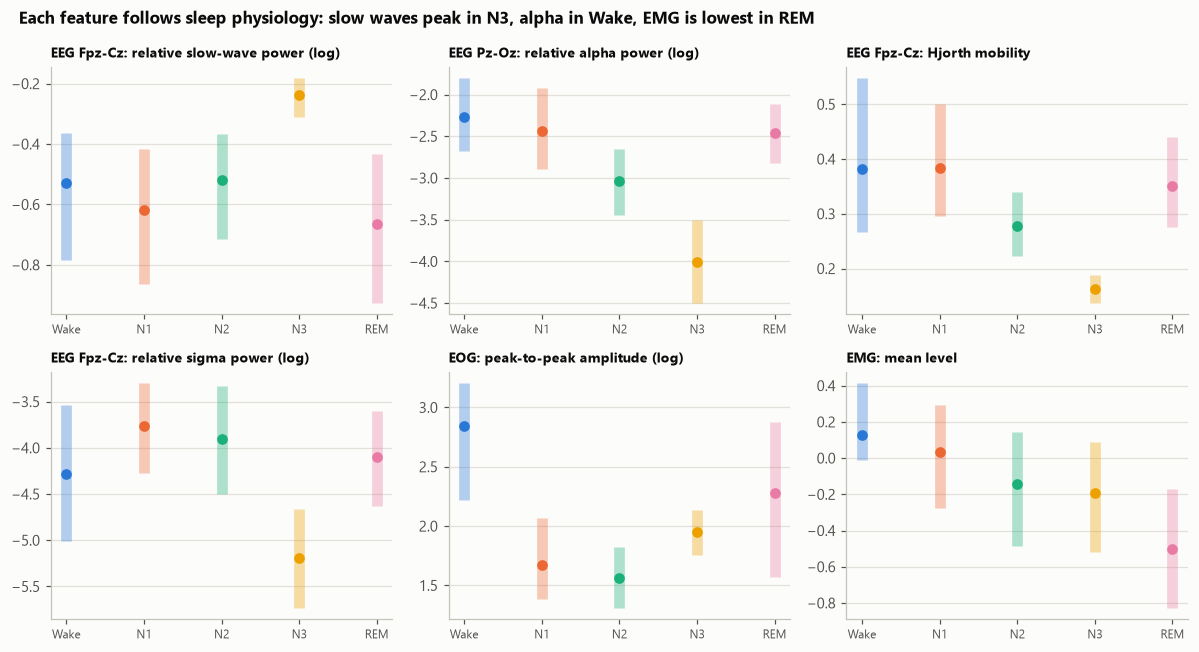

,fpz_rel_delta1,pz_rel_alpha,fpz_mobility,fpz_rel_sigma,eog_log_ptp,emg_mean
Wake,-0.53,-2.27,0.38,-4.28,2.84,0.13
N1,-0.62,-2.44,0.38,-3.76,1.67,0.04
N2,-0.52,-3.03,0.28,-3.91,1.56,-0.15
N3,-0.24,-4.01,0.16,-5.19,1.95,-0.19
REM,-0.67,-2.46,0.35,-4.10,2.28,-0.50


In [4]:
show = {"fpz_rel_delta1": "EEG Fpz-Cz: relative slow-wave power (log)",
        "pz_rel_alpha": "EEG Pz-Oz: relative alpha power (log)",
        "fpz_mobility": "EEG Fpz-Cz: Hjorth mobility",
        "fpz_rel_sigma": "EEG Fpz-Cz: relative sigma power (log)",
        "eog_log_ptp": "EOG: peak-to-peak amplitude (log)",
        "emg_mean": "EMG: mean level"}
scored = y >= 0
fig, axes = plt.subplots(2, 3, figsize=(11, 6))
for ax, (col, title) in zip(axes.flat, show.items()):
    v = X_base[scored, FEATURE_NAMES.index(col)]
    for s, name in enumerate(STAGES):
        q1, q2, q3 = np.percentile(v[y[scored] == s], [25, 50, 75])
        ax.vlines(s, q1, q3, color=STAGE_COLORS[name], lw=7, alpha=0.35)
        ax.plot(s, q2, "o", color=STAGE_COLORS[name], ms=6)
    ax.set_xticks(range(5), STAGES, fontsize=8)
    ax.set_title(title, fontsize=9)
fig.suptitle("Each feature follows sleep physiology: slow waves peak in N3, alpha in Wake, EMG is lowest in REM",
             x=0.02, ha="left", fontweight="bold", fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_features_by_stage.png")
plt.show()

pd.DataFrame(X_base[scored], columns=FEATURE_NAMES)[list(show)].groupby(
    pd.Categorical(np.array(STAGES)[y[scored]], STAGES), observed=True).median().round(2)

**Input.** Menggambar median dan rentang antar-kuartil enam fitur per tahap tidur pada seluruh *epoch* berlabel, ditambah tabel mediannya.

**Output.** Daya gelombang lambat relatif tertinggi saat N3; daya alfa di Pz-Oz (kanal oksipital) tertinggi saat *Wake*; *Hjorth mobility* (frekuensi rata-rata) terendah saat N3; amplitudo EOG tertinggi saat *Wake* dan REM; tingkat EMG turun berurutan dari *Wake* ke REM. Satu pengecualian: daya sigma relatif di Fpz-Cz tidak tertinggi saat N2, sehingga ciri *sleep spindle* tidak menonjol pada fitur ini.

**Kesimpulan.** Fitur mengikuti fisiologi tidur, jadi perhitungannya benar. Keterbatasan fitur sigma adalah satu alasan model *deep learning*, yang belajar polanya sendiri, berpotensi lebih baik.

## Bagian E. Fitur konteks

Tahap tidur mengalir, sehingga *epoch* tetangga ikut membantu. Fitur dua *epoch* sebelum dan sesudahnya ditempelkan ke setiap baris.

In [5]:
def add_context(X, rec, k=CONTEXT):
    """Append the features of the k previous and k next epochs; NaN where the neighbour is in another recording."""
    blocks = [X]
    for shift in [*range(-k, 0), *range(1, k + 1)]:
        neighbour = np.roll(X, -shift, axis=0)                 # row i now holds epoch i + shift
        neighbour[np.roll(rec, -shift) != rec] = np.nan        # neighbour belongs to another recording (or wrapped)
        blocks.append(neighbour)
    return np.hstack(blocks)


SHIFTS = [*range(-CONTEXT, 0), *range(1, CONTEXT + 1)]
COLUMNS = FEATURE_NAMES + [f"{name}@{s:+d}" for s in SHIFTS for name in FEATURE_NAMES]
X_ctx = add_context(X_base, rec)

n_rec = len(np.unique(rec))
assert X_ctx.shape == (len(y), 33 * (1 + 2 * CONTEXT))
assert np.isnan(X_ctx).sum() == n_rec * sum(abs(s) for s in SHIFTS) * 33   # missing neighbours only at recording edges
i = np.flatnonzero(rec == "SC4001E")[10]                                   # an epoch in the middle of a recording
assert np.array_equal(X_ctx[i, COLUMNS.index("fpz_log_total@+1")], X_base[i + 1, 0])
print(f"{X_ctx.shape[1]} columns = 33 features x {1 + 2 * CONTEXT} epochs; "
      f"{np.isnan(X_ctx).sum():,} missing values, all at recording edges")

165 columns = 33 features x 5 epochs; 30,294 missing values, all at recording edges


**Input.** Menempelkan fitur dua *epoch* sebelum dan sesudah ke setiap baris. Tetangga yang berasal dari rekaman lain (di tepi rekaman) diisi NaN; *gradient boosting* dapat menangani nilai kosong.

**Output.** 165 kolom (33 fitur × 5 *epoch*) dan 30.294 nilai kosong.

**Kesimpulan.** Jumlah nilai kosong tepat 153 rekaman × 6 posisi tepi × 33 fitur, dan nilai tetangga dicek sama dengan *epoch* sebenarnya. Tidak ada tetangga yang bocor dari rekaman lain.

## Bagian F. Model dan skema validasi

Menetapkan model, metrik, dan cara membagi data latih, validasi, dan uji berdasarkan **subjek**, sehingga subjek uji tidak pernah dilihat saat pelatihan.

In [6]:
def model():
    """Gradient boosting with class weights; early stopping on held-out validation subjects."""
    return HistGradientBoostingClassifier(max_iter=500, learning_rate=0.1, max_leaf_nodes=31,
                                          max_bins=63,            # coarser histograms: ~2x faster, same MF1 in tests
                                          early_stopping=True, scoring="loss", n_iter_no_change=20,
                                          class_weight="balanced", random_state=SEED)


def summarise(y_true, y_pred):
    f1 = f1_score(y_true, y_pred, labels=range(5), average=None)
    return {"ACC": accuracy_score(y_true, y_pred), "MF1": f1.mean(), "kappa": cohen_kappa_score(y_true, y_pred),
            **{f"F1_{s}": v for s, v in zip(STAGES, f1)}}


def cross_validate(X, y, groups, splitter, importance_groups=None):
    """Train/test across folds; ~10% of training groups are held out as validation for early stopping.
    Returns pooled out-of-fold predictions (IGNORE for unlabelled epochs), per-fold MF1 and, optionally,
    the mean MF1 drop when each column group is permuted in the test fold."""
    scored = np.flatnonzero(y >= 0)
    Xs, ys, gs = X[scored], y[scored], groups[scored]
    pred = np.full(len(y), IGNORE, dtype=np.int8)
    fold_mf1, drops = [], {g: [] for g in (importance_groups or {})}
    rng = np.random.default_rng(SEED)
    for fold, (train, test) in enumerate(splitter.split(Xs, ys, gs)):
        inner = GroupShuffleSplit(n_splits=1, test_size=0.1, random_state=SEED + fold)
        fit, val = (train[i] for i in next(inner.split(train, groups=gs[train])))
        assert not set(gs[fit]) & set(gs[val]) and not set(gs[train]) & set(gs[test])   # no group in two sets
        clf = model().fit(Xs[fit], ys[fit], X_val=Xs[val], y_val=ys[val])
        p = clf.predict(Xs[test])
        pred[scored[test]] = p
        fold_mf1.append(f1_score(ys[test], p, labels=range(5), average="macro"))
        for g, cols in (importance_groups or {}).items():
            Xp = Xs[test].copy()
            Xp[:, cols] = Xp[rng.permutation(len(test))][:, cols]               # shuffle one group across epochs
            drops[g].append(fold_mf1[-1] - f1_score(ys[test], clf.predict(Xp), labels=range(5), average="macro"))
    importance = pd.Series({g: np.mean(v) for g, v in drops.items()}).sort_values(ascending=False) if drops else None
    return pred, np.array(fold_mf1), importance


sc20 = subject < 20
print(f"SC-20: {sc20.sum():,} epochs, {len(np.unique(subject[sc20]))} subjects; "
      f"SC-78: {len(y):,} epochs, {len(np.unique(subject))} subjects")

SC-20: 42,368 epochs, 20 subjects; SC-78: 195,767 epochs, 78 subjects


**Input.** Mendefinisikan model (*gradient boosting* dengan bobot kelas seimbang), metrik (akurasi, Macro-F1, Kappa, F1 per kelas), dan fungsi validasi silang. Di setiap lipatan, sekitar 10% subjek latih disisihkan sebagai validasi untuk menghentikan pelatihan saat *log-loss* validasi tidak membaik 20 iterasi. *Epoch* berlabel −1 tidak dilatih maupun dinilai. `assert` memastikan subjek latih, validasi, dan uji tidak tumpang tindih.

**Output.** Ukuran SC-20 (42.368 *epoch*, 20 subjek) dan SC-78 (195.767 *epoch*, 78 subjek).

**Kesimpulan.** Kerangka evaluasi siap dan sama untuk semua eksperimen berikutnya, sehingga hasil dapat dibandingkan dengan adil.

## Bagian G. Hasil utama

Hasil pada SC-20 (satu subjek per lipatan, 20 lipatan) dan SC-78 (10 lipatan), sesuai protokol yang lazim di literatur.

In [7]:
t0 = time.time()
pred20, folds20, _ = cross_validate(X_ctx[sc20], y[sc20], subject[sc20], LeaveOneGroupOut())
y20 = y[sc20]
res20 = summarise(y20[y20 >= 0], pred20[y20 >= 0])
print(f"SC-20, {len(folds20)} folds (one subject each), {time.time() - t0:.0f} s: "
      f"MF1 {100 * res20['MF1']:.1f}, kappa {res20['kappa']:.3f}; per-fold MF1 {100 * folds20.mean():.1f} ± {100 * folds20.std():.1f}")

SC-20, 20 folds (one subject each), 211 s: MF1 79.2, kappa 0.784; per-fold MF1 78.6 ± 5.8


**Input.** Validasi silang SC-20 dengan satu subjek per lipatan (20 lipatan).

**Output.** MF1 79,2, Kappa 0,784, dan rerata MF1 per lipatan 78,6 ± 5,8 (sekitar 3 menit).

**Kesimpulan.** Rentang ±5,8 menunjukkan skor cukup bervariasi antar-subjek.

In [8]:
by_feature = {name: [COLUMNS.index(c) for c in COLUMNS if c.split("@")[0] == name] for name in FEATURE_NAMES}
by_modality = {m: [i for i, c in enumerate(COLUMNS) if c.startswith(m + "_")] for m in ["fpz", "pz", "eog", "emg"]}

t0 = time.time()
pred78, folds78, importance = cross_validate(X_ctx, y, subject, GroupKFold(n_splits=10),
                                             importance_groups={**by_modality, **by_feature})
res78 = summarise(y[y >= 0], pred78[y >= 0])
print(f"SC-78, {len(folds78)} folds, {time.time() - t0:.0f} s: "
      f"MF1 {100 * res78['MF1']:.1f}, kappa {res78['kappa']:.3f}; per-fold MF1 {100 * folds78.mean():.1f} ± {100 * folds78.std():.1f}")

SC-78, 10 folds, 694 s: MF1 76.5, kappa 0.739; per-fold MF1 76.4 ± 2.4


**Input.** Validasi silang SC-78 dengan 10 lipatan berbasis subjek. Di setiap lipatan juga dihitung pentingnya fitur: satu kelompok kolom diacak antar-*epoch* pada data uji, lalu diukur seberapa besar MF1 turun.

**Output.** MF1 76,5, Kappa 0,739, dan rerata MF1 per lipatan 76,4 ± 2,4 (sekitar 11 menit).

**Kesimpulan.** Skor SC-78 lebih rendah daripada SC-20 karena SC-78 memuat subjek lanjut usia yang lebih sulit (lihat H4).

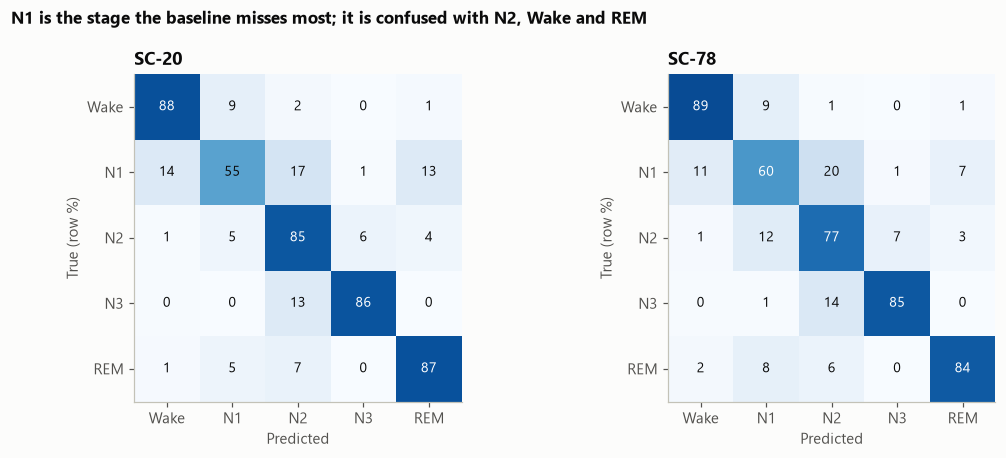

,ACC,MF1,F1_Wake,F1_N1,F1_N2,F1_N3,F1_REM,kappa,MF1 per fold
SC-20 (20 folds),84.1,79.2,89.8,49.3,86.8,83.6,86.5,0.784,78.6 ± 5.8
SC-78 (10 folds),80.7,76.5,91.8,51.0,81.5,74.6,83.5,0.739,76.4 ± 2.4


In [9]:
results = pd.DataFrame({"SC-20 (20 folds)": res20, "SC-78 (10 folds)": res78}).T
results["MF1 per fold"] = [f"{100 * folds20.mean():.1f} ± {100 * folds20.std():.1f}",
                           f"{100 * folds78.mean():.1f} ± {100 * folds78.std():.1f}"]
results.to_csv(TAB_DIR / "03_baseline_metrics.csv")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, (title, yt, yp) in zip(axes, [("SC-20", y20, pred20), ("SC-78", y, pred78)]):
    cm = confusion_matrix(yt[yt >= 0], yp[yt >= 0], labels=range(5))
    cm = 100 * cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=100)
    for r in range(5):
        for c in range(5):
            ax.text(c, r, f"{cm[r, c]:.0f}", ha="center", va="center", fontsize=9,
                    color="white" if cm[r, c] > 60 else INK)
    ax.set_xticks(range(5), STAGES)
    ax.set_yticks(range(5), STAGES)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True (row %)")
    ax.grid(False)
    ax.set_title(title)
fig.suptitle("N1 is the stage the baseline misses most; it is confused with N2, Wake and REM",
             x=0.02, ha="left", fontweight="bold", fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_baseline_confusion.png")
plt.show()

(100 * results[["ACC", "MF1", *[f"F1_{s}" for s in STAGES]]]).round(1).assign(
    kappa=results["kappa"].round(3), **{"MF1 per fold": results["MF1 per fold"]})

**Input.** Merangkum metrik kedua dataset ke tabel `results/tables/03_baseline_metrics.csv` dan menggambar matriks konfusi (persentase per baris: dari seluruh *epoch* tahap tertentu, berapa persen ditebak sebagai tahap apa).

**Output.**

| | ACC | MF1 | F1 Wake | F1 N1 | F1 N2 | F1 N3 | F1 REM | Kappa |
|---|---|---|---|---|---|---|---|---|
| SC-20 | 84,1 | 79,2 | 89,8 | 49,3 | 86,8 | 83,6 | 86,5 | 0,784 |
| SC-78 | 80,7 | 76,5 | 91,8 | 51,0 | 81,5 | 74,6 | 83,5 | 0,739 |

Pada matriks konfusi, N1 hanya benar 55% (SC-20) dan 60% (SC-78); sisanya terutama tertebak sebagai N2 (17% dan 20%), *Wake* (14% dan 11%), dan REM (13% dan 7%). N3 tertebak sebagai N2 sekitar 13 sampai 14%.

**Kesimpulan.** N1 adalah kelas tersulit, sesuai literatur dan kesepakatan antar-dokter yang rendah untuk N1 (sekitar 63%). Angka ini menjadi **batas bawah Fase 3**. Skor ini sudah dekat dengan beberapa model *deep learning* di literatur (misalnya DeepSleepNet MF1 76,9 pada SC-20), meski protokolnya tidak persis sama sehingga perbandingan langsung harus hati-hati.

## Bagian H. Analisis tambahan

Empat analisis untuk memahami hasil: kontribusi tiap modalitas, besar kebocoran data bila pembagian salah, fitur yang paling diandalkan, dan skor per subjek menurut usia.

In [10]:
def cols_of(blocks, context=True):
    """Column indices for the chosen feature blocks, with or without the neighbouring-epoch copies."""
    return [i for i, c in enumerate(COLUMNS) if c.split("_")[0] in blocks and (context or "@" not in c)]


ABLATION = {"EEG Fpz-Cz": cols_of({"fpz"}, context=False),
            "+ EEG Pz-Oz": cols_of({"fpz", "pz"}, context=False),
            "+ EOG": cols_of({"fpz", "pz", "eog"}, context=False),
            "+ EMG": cols_of({"fpz", "pz", "eog", "emg"}, context=False),
            "+ context ±2 (main model)": cols_of({"fpz", "pz", "eog", "emg"})}

t0 = time.time()
rows = {}
for name, cols in ABLATION.items():
    if name.startswith("+ context"):
        p = pred20                                          # identical configuration, already computed in G1
    else:
        p, _, _ = cross_validate(X_ctx[sc20][:, cols], y20, subject[sc20], LeaveOneGroupOut())
    rows[name] = {"features": len(cols), **summarise(y20[y20 >= 0], p[y20 >= 0])}
ablation = pd.DataFrame(rows).T
print(f"SC-20 ablation in {time.time() - t0:.0f} s")
(100 * ablation[["MF1", *[f"F1_{s}" for s in STAGES]]]).round(1).assign(
    features=ablation["features"].astype(int), kappa=ablation["kappa"].astype(float).round(3))

SC-20 ablation in 234 s


,MF1,F1_Wake,F1_N1,F1_N2,F1_N3,F1_REM,features,kappa
EEG Fpz-Cz,68.4,76.7,29.3,84.3,83.1,68.4,12,0.665
+ EEG Pz-Oz,72.5,85.3,34.6,84.8,84.0,73.9,24,0.712
+ EOG,75.1,86.0,41.7,85.3,83.2,79.1,29,0.736
+ EMG,76.6,87.4,43.7,85.4,83.6,82.9,33,0.754
+ context ±2 (main model),79.2,89.8,49.3,86.8,83.6,86.5,165,0.784


**Input.** Ablasi modalitas pada SC-20: model dilatih ulang dengan masukan yang ditambah bertahap (Fpz-Cz saja, + Pz-Oz, + EOG, + EMG, + konteks). Konfigurasi terakhir sama dengan hasil utama G1 sehingga tidak dihitung ulang.

**Output.** MF1 naik 68,4 → 72,5 → 75,1 → 76,6 → 79,2. F1-N1 naik 29,3 → 34,6 → 41,7 → 43,7 → 49,3, dan F1-REM naik 68,4 → 73,9 → 79,1 → 82,9 → 86,5.

**Kesimpulan.** Setiap modalitas menambah skor. EOG dan EMG paling membantu REM, sesuai fisiologinya (gerakan mata dan kelumpuhan otot), dan konteks antar-*epoch* memberi tambahan terbesar kedua. Ini bukti awal untuk desain multimodal dan *Bi-LSTM* di Fase 3.

In [11]:
t0 = time.time()
epoch_ids = np.arange(sc20.sum())                       # every epoch is its own group: a random split by epoch
pred_leak, folds_leak, _ = cross_validate(X_ctx[sc20], y20, epoch_ids,
                                          GroupKFold(n_splits=20, shuffle=True, random_state=SEED))
res_leak = summarise(y20[y20 >= 0], pred_leak[y20 >= 0])
leakage = pd.DataFrame({"by subject (correct)": res20, "by epoch (leaky)": res_leak}).T
print(f"Leakage check in {time.time() - t0:.0f} s: random epoch split inflates MF1 by "
      f"{100 * (res_leak['MF1'] - res20['MF1']):.1f} points")
(100 * leakage[["ACC", "MF1", "F1_N1"]]).round(1).assign(kappa=leakage["kappa"].round(3))

Leakage check in 326 s: random epoch split inflates MF1 by 7.0 points


,ACC,MF1,F1_N1,kappa
by subject (correct),84.1,79.2,49.3,0.784
by epoch (leaky),90.0,86.2,63.6,0.863


**Input.** Model yang sama dilatih dengan pembagian **acak per *epoch*** (20 lipatan), sehingga *epoch* dari subjek yang sama bisa berada di data latih dan uji sekaligus. Hasilnya dibandingkan dengan pembagian per subjek dari G1.

**Output.** Pembagian per *epoch* menghasilkan MF1 86,2, Kappa 0,863, dan F1-N1 63,6, dibanding 79,2, 0,784, dan 49,3 pada pembagian per subjek: MF1 naik 7,0 poin.

**Kesimpulan.** Kenaikan itu palsu: model "mengenali orangnya", bukan tahap tidurnya. Ini alasan seluruh evaluasi proyek wajib berbasis subjek. Eksperimen yang sama akan diulang pada model akhir (keputusan K3).

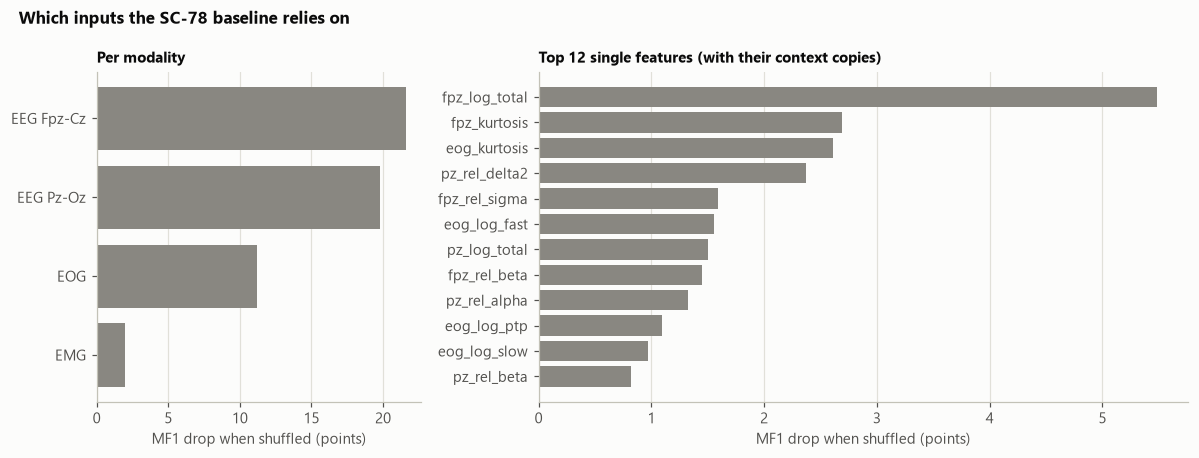

,MF1 drop (points)
fpz,21.60
pz,19.77
eog,11.19
fpz_log_total,5.48
fpz_kurtosis,2.69
eog_kurtosis,2.61
pz_rel_delta2,2.37
emg,1.94
fpz_rel_sigma,1.59
eog_log_fast,1.56


In [12]:
NICE = {"fpz": "EEG Fpz-Cz", "pz": "EEG Pz-Oz", "eog": "EOG", "emg": "EMG"}
top = importance.drop(list(by_modality)).head(12)[::-1]
mod = importance[list(by_modality)].sort_values()
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1, 2]})
axes[0].barh([NICE[m] for m in mod.index], 100 * mod.values, color=MUTED)
axes[0].set_title("Per modality", fontsize=10)
axes[0].set_xlabel("MF1 drop when shuffled (points)")
axes[1].barh(top.index, 100 * top.values, color=MUTED)
axes[1].set_title("Top 12 single features (with their context copies)", fontsize=10)
axes[1].set_xlabel("MF1 drop when shuffled (points)")
for ax in axes:
    ax.grid(axis="x", color=GRID)
    ax.grid(axis="y", visible=False)
fig.suptitle("Which inputs the SC-78 baseline relies on", x=0.02, ha="left", fontweight="bold", fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_feature_importance.png")
plt.show()
(100 * importance).round(2).rename("MF1 drop (points)").head(15).to_frame()

**Input.** Menampilkan pentingnya fitur dari G2: penurunan MF1 bila satu kelompok kolom diacak, per modalitas (kiri) dan per fitur beserta salinan konteksnya (kanan).

**Output.** Mengacak EEG Fpz-Cz menurunkan MF1 sekitar 21,6 poin, EEG Pz-Oz 19,8, EOG 11,2, dan EMG hanya 1,9. Fitur tunggal terpenting adalah daya total Fpz-Cz (5,5 poin), diikuti kurtosis Fpz-Cz dan EOG serta daya delta Pz-Oz.

**Kesimpulan.** Model paling bergantung pada EEG. EMG tampak kecil di sini karena metode pengacakan hanya mengukur informasi yang **tidak** dimiliki fitur lain; ablasi H1 tetap menunjukkan EMG menambah 1,5 poin MF1 dan 3,8 poin F1-REM. Kedua ukuran saling melengkapi.

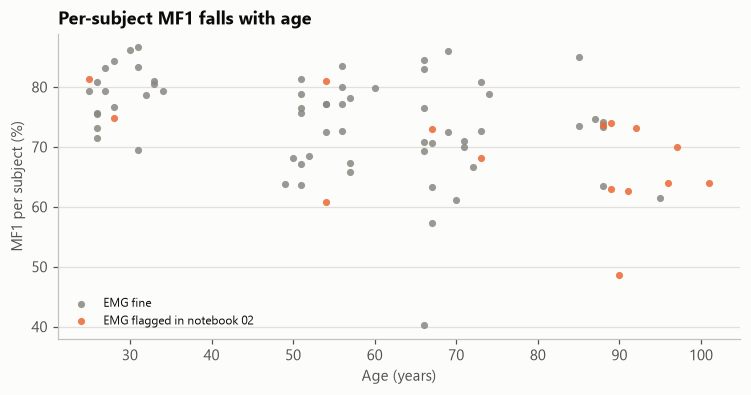

Correlation of age with per-subject MF1: -0.43; MF1 74.3 for 63 subjects with fine EMG vs 68.8 for 15 subjects with flagged EMG


,subjects,MF1_mean,MF1_sd
age group,,,
25-39,20,79.0,4.7
40-59,21,73.2,6.7
60-79,21,71.2,10.4
80+,16,68.7,8.3


In [13]:
manifest = pd.read_csv(MANIFEST, index_col="rec")
rows = []
for s in np.unique(subject):
    m = (subject == s) & (y >= 0)
    recs = np.unique(rec[m])
    rows.append({"subject": int(s), "age": int(age[m][0]), "epochs": int(m.sum()),
                 "MF1": f1_score(y[m], pred78[m], labels=np.unique(y[m]), average="macro"),
                 "emg_flag": bool(manifest.loc[recs, "flag_emg"].any())})
per_subject = pd.DataFrame(rows).set_index("subject")
per_subject["age group"] = pd.cut(per_subject["age"], [24, 39, 59, 79, 120], labels=["25-39", "40-59", "60-79", "80+"])

fig, ax = plt.subplots(figsize=(8, 3.6))
for flag, colour, label in [(False, MUTED, "EMG fine"), (True, STAGE_COLORS["N1"], "EMG flagged in notebook 02")]:
    d = per_subject[per_subject["emg_flag"] == flag]
    ax.scatter(d["age"], 100 * d["MF1"], s=22, color=colour, label=label, alpha=0.85, linewidths=0)
ax.set_xlabel("Age (years)")
ax.set_ylabel("MF1 per subject (%)")
ax.legend(frameon=False, fontsize=8)
ax.set_title("Per-subject MF1 falls with age")
fig.savefig(FIG_DIR / "03_per_subject_mf1.png")
plt.show()

flag = per_subject.groupby("emg_flag")["MF1"].agg(["size", "mean"])
print(f"Correlation of age with per-subject MF1: {per_subject['age'].corr(per_subject['MF1']):.2f}; "
      f"MF1 {100 * flag.loc[False, 'mean']:.1f} for {flag.loc[False, 'size']} subjects with fine EMG vs "
      f"{100 * flag.loc[True, 'mean']:.1f} for {flag.loc[True, 'size']} subjects with flagged EMG")

per_subject.groupby("age group", observed=True).agg(subjects=("MF1", "size"), MF1_mean=("MF1", "mean"),
                                                    MF1_sd=("MF1", "std")).assign(
    MF1_mean=lambda d: (100 * d["MF1_mean"]).round(1), MF1_sd=lambda d: (100 * d["MF1_sd"]).round(1))

**Input.** Menghitung MF1 tiap subjek pada SC-78 dan mengelompokkannya menurut usia, serta menandai subjek yang EMG-nya ditandai bermasalah di notebook 02.

**Output.** Rerata MF1 per subjek: 79,0 (usia 25–39), 73,2 (40–59), 71,2 (60–79), dan 68,7 (80 tahun ke atas). Korelasi usia dengan MF1 −0,43. Subjek dengan EMG bermasalah rata-rata 68,8, dibanding 74,3 untuk lainnya.

**Kesimpulan.** Model makin sulit pada subjek lanjut usia, sejalan dengan berkurangnya N3 dan bertambahnya fragmentasi tidur pada usia tua. Selisih pada subjek ber-EMG bermasalah sebagian besar tumpang tindih dengan efek usia, karena kebanyakan dari mereka lansia. Hasil ini perlu dilaporkan terstratifikasi usia.

## Bagian I. Penyimpanan hasil

Menyimpan tabel hasil dan prediksi sebagai pembanding untuk Fase 3.

In [14]:
ablation.to_csv(TAB_DIR / "03_baseline_ablation.csv")
leakage.to_csv(TAB_DIR / "03_baseline_leakage.csv")
importance.rename("mf1_drop").to_csv(TAB_DIR / "03_baseline_importance.csv")
per_subject.to_csv(TAB_DIR / "03_baseline_per_subject.csv")
pred_sc20 = np.full(len(y), IGNORE, dtype=np.int8)
pred_sc20[sc20] = pred20                                   # SC-20 predictions placed back on the full epoch list
np.savez(PREDICTIONS, rec=rec, epoch_idx=data["epoch_idx"], y=y, pred_sc20=pred_sc20, pred_sc78=pred78)
saved = sorted(p.name for p in TAB_DIR.glob("03_*.csv"))
print("tables:", saved)
print(f"Baseline to beat in phase 3: SC-20 MF1 {100 * res20['MF1']:.1f} / kappa {res20['kappa']:.3f}; "
      f"SC-78 MF1 {100 * res78['MF1']:.1f} / kappa {res78['kappa']:.3f}")

tables: ['03_baseline_ablation.csv', '03_baseline_importance.csv', '03_baseline_leakage.csv', '03_baseline_metrics.csv', '03_baseline_per_subject.csv']
Baseline to beat in phase 3: SC-20 MF1 79.2 / kappa 0.784; SC-78 MF1 76.5 / kappa 0.739


**Input.** Menyimpan tabel ablasi, kebocoran, pentingnya fitur, dan skor per subjek ke `results/tables/`, serta prediksi SC-20 dan SC-78 ke `data/processed/baseline_predictions.npz`.

**Output.** Daftar tabel yang tersimpan dan ringkasan angka pembanding.

**Kesimpulan.** Batas bawah untuk Fase 3 adalah **MF1 79,2 / Kappa 0,784 pada SC-20** dan **MF1 76,5 / Kappa 0,739 pada SC-78**, dihitung dengan protokol berbasis subjek yang sama dengan yang akan dipakai model *deep learning*.